In [1]:
OUTPUT = "../submission"

In [2]:
# Carga de datos


def load_data():

    from sklearn.datasets import load_digits

    digits = load_digits()
    x = digits.data
    y = digits.target

    return x, y

In [3]:
# Gráfica del embedding


def plot_embedding(embedding, y, method, filename, s=6):

    import os

    import matplotlib.pyplot as plt

    if not os.path.exists(OUTPUT):
        os.makedirs(OUTPUT)

    fig, ax = plt.subplots(figsize=(8, 8))
    plt.scatter(embedding[:, 0], embedding[:, 1], c=y, cmap="Spectral", s=s)
    plt.setp(ax, xticks=[], yticks=[])
    plt.title(f"Digits data embedded into two dimensions by {method}", fontsize=18)
    plt.savefig(f"{OUTPUT}/{filename}")
    plt.show()

In [4]:
# Principal Component Analysis (PCA)


def pca():

    from sklearn.decomposition import PCA

    x, y = load_data()

    reducer = PCA(n_components=2)
    embedding = reducer.fit_transform(x)

    plot_embedding(embedding, y, method="PCA", filename="digits_pca.png")


pca()

<Figure size 800x800 with 1 Axes>

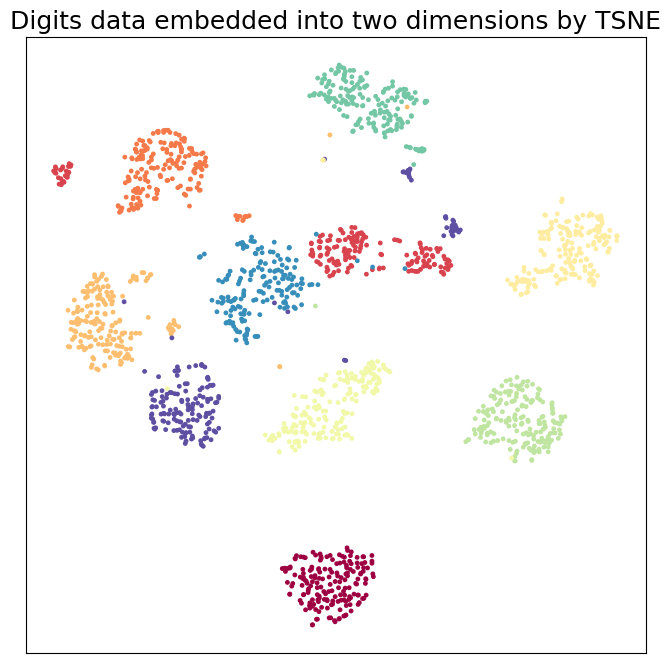

In [5]:
# t-distributed Stochastic Neighbor Embedding (t-SNE)


def tsne():

    from sklearn.manifold import TSNE

    x, y = load_data()

    reducer = TSNE(n_components=2, random_state=0)
    embedding = reducer.fit_transform(x)

    plot_embedding(embedding, y, method="TSNE", filename="digits_tsne.png")


tsne()

c:\Users\diana\OneDrive\Documents\GitHub\std-diana-esther-gonzalez-salgado\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\diana\OneDrive\Documents\GitHub\std-diana-esther-gonzalez-salgado\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


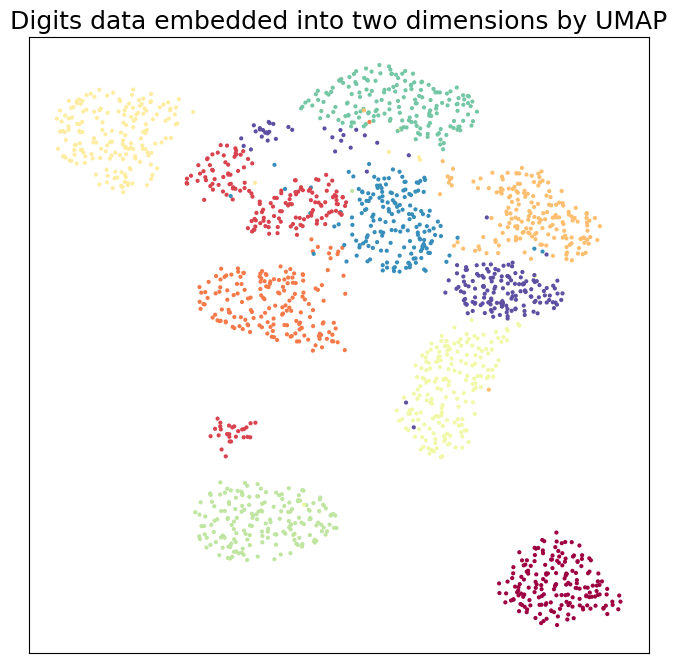

In [6]:
# Uniform Manifold Approximation and Projection (UMAP)


def umap():

    import umap

    x, y = load_data()

    reducer = umap.UMAP(random_state=42, min_dist=0.8)
    embedding = reducer.fit_transform(x)

    plot_embedding(embedding, y, method="UMAP", filename="digits_umap.png", s=4)


umap()

In [7]:
# Particionamiento de datos


def make_train_test_split(x, y):

    from sklearn.model_selection import train_test_split

    (x_train, x_test, y_train, y_test) = train_test_split(
        x,
        y,
        test_size=0.50,
        random_state=0,
        stratify=y,
    )
    return x_train, x_test, y_train, y_test

In [8]:
# ¿Cuántas componentes principales conservan suficiente información para
# clasificar el dígito, no sólo para verse bien en un gráfico?

COMPONENTS = [2, 5, 10, 20, 30, 40, 64]


def pca_components_accuracy():

    import pandas as pd
    from sklearn.decomposition import PCA
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    x, y = load_data()
    x_train, x_test, y_train, y_test = make_train_test_split(x, y)

    results = []

    for k in COMPONENTS:
        pipeline = Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("pca", PCA(n_components=k)),
                ("estimator", LogisticRegression(max_iter=1000)),
            ],
        )
        pipeline.fit(x_train, y_train)
        results.append(
            {
                "k": k,
                "explained_variance": pipeline.named_steps[
                    "pca"
                ].explained_variance_ratio_.sum(),
                "test_accuracy": pipeline.score(x_test, y_test),
            }
        )

    return pd.DataFrame(results)


pca_results = pca_components_accuracy()
pca_results

,k,explained_variance,test_accuracy
0,2,0.219732,0.543938
1,5,0.423248,0.812013
2,10,0.604982,0.880979
3,20,0.806500,0.935484
4,30,0.908787,0.942158
5,40,0.959915,0.952169
6,64,1.000000,0.963293


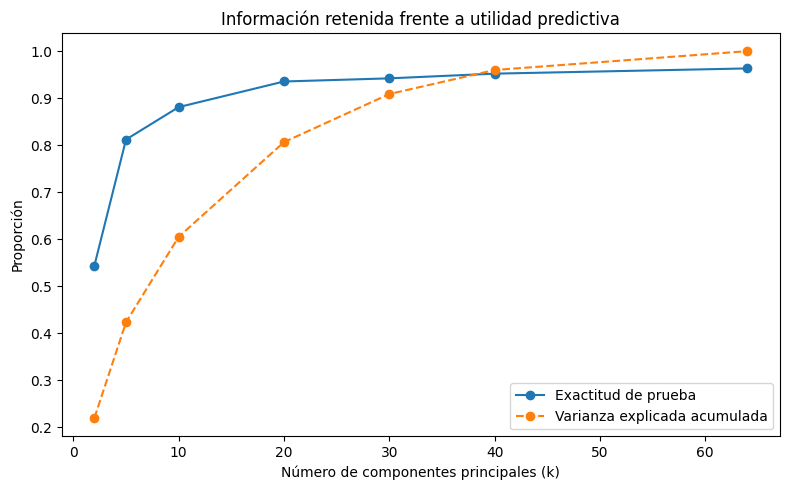

In [9]:
# La gráfica muestra si la exactitud de prueba sigue subiendo después de que
# la varianza explicada ya está casi completa.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    pca_results["k"],
    pca_results["test_accuracy"],
    marker="o",
    label="Exactitud de prueba",
)
ax.plot(
    pca_results["k"],
    pca_results["explained_variance"],
    marker="o",
    linestyle="--",
    label="Varianza explicada acumulada",
)
ax.set_xlabel("Número de componentes principales (k)")
ax.set_ylabel("Proporción")
ax.set_title("Información retenida frente a utilidad predictiva")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# ¿UMAP, que sí admite proyectar observaciones nuevas, retiene tanta
# información predictiva como PCA con el mismo número de componentes?


def umap_components_accuracy():

    import pandas as pd
    import umap
    from sklearn.linear_model import LogisticRegression

    x, y = load_data()
    x_train, x_test, y_train, y_test = make_train_test_split(x, y)

    results = []

    for k in COMPONENTS:
        reducer = umap.UMAP(n_components=k, random_state=42, min_dist=0.8)
        reducer.fit(x_train)

        estimator = LogisticRegression(max_iter=1000)
        estimator.fit(reducer.transform(x_train), y_train)

        results.append(
            {
                "k": k,
                "test_accuracy": estimator.score(reducer.transform(x_test), y_test),
            }
        )

    return pd.DataFrame(results)


umap_results = umap_components_accuracy()
umap_results

c:\Users\diana\OneDrive\Documents\GitHub\std-diana-esther-gonzalez-salgado\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\diana\OneDrive\Documents\GitHub\std-diana-esther-gonzalez-salgado\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\diana\OneDrive\Documents\GitHub\std-diana-esther-gonzalez-salgado\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _che

,k,test_accuracy
0,2,0.867631
1,5,0.939933
2,10,0.949944
3,20,0.942158
4,30,0.949944
5,40,0.943270
6,64,0.944383


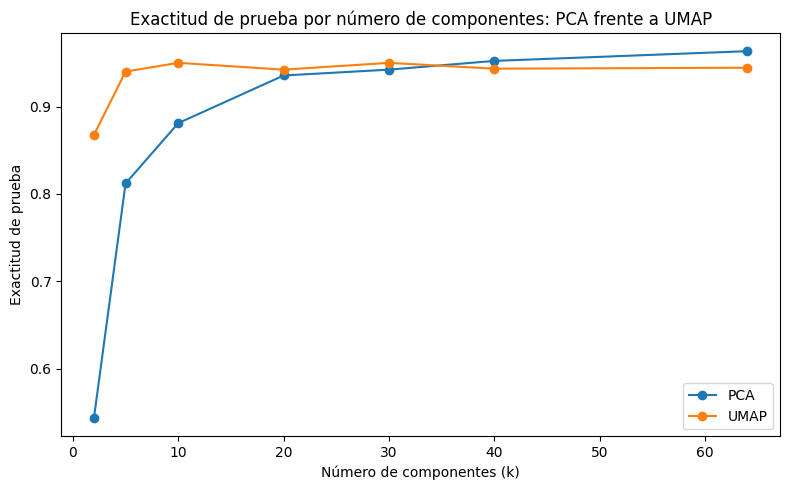

In [11]:
# Comparación PCA frente a UMAP

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pca_results["k"], pca_results["test_accuracy"], marker="o", label="PCA")
ax.plot(umap_results["k"], umap_results["test_accuracy"], marker="o", label="UMAP")
ax.set_xlabel("Número de componentes (k)")
ax.set_ylabel("Exactitud de prueba")
ax.set_title("Exactitud de prueba por número de componentes: PCA frente a UMAP")
ax.legend()
plt.tight_layout()
plt.show()